# All seven windows: the final-evaluation candidates side by side

The ten candidates of the final evaluation on **all seven test windows**: the six windows
used during development (W1–W6, 720 test dates, 2022-12-29 → 2025-12-18) and the final
window (W7, 84 test dates, 2025-12-19 → 2026-04-28), 804 test dates in all. Every column is
scored on the same dates and stocks, and compared with **Run-2** (the author's baseline)
paired day by day.

- **Sources:** W1–W6 from the archived runs (`runs/run-N_*`); W7 from `runs/run-final/`
  (trained by `train_final-window.py`). Nothing is retrained here.
- **New in this notebook:** the two weighted mixes on W1–W6. Their weights are fitted here,
  window by window, with the same rule `runs/run-final/post-processing.ipynb` used for W7
  (footnote \*\*).
- **Read with care:** W1–W6 were used to design and choose every setup in this table, so
  their numbers flatter the chosen ones. W7 is the only window no choice was based on; the
  pre-registered verdict on it is in `final-evaluation_performances.ipynb`. The W7 rows here
  reproduce that notebook's numbers.

The setup rows, then the metric rows, then the footnotes (marks \*, \*\*, †, †† and
numbers in brackets) that define every term.

In [6]:
import json
import math
import os
import warnings
from pathlib import Path

import numpy as np
import polars as pl
from IPython.display import HTML, display
from scipy.optimize import minimize

ROOT = Path(os.environ.get("TS48_ROOT", Path.cwd())).resolve()  # The repo root; TS48_ROOT overrides (tests).
RUNS = ROOT / "runs"
FINAL_DIR = RUNS / "run-final"
DATA_FILE = ROOT / "data.parquet"
NW_LAGS = 4
Z95 = 1.96
warnings.filterwarnings("ignore", message=".*non-interactive.*")

SETUPS = ["run-2", "run-5", "run-11", "run-13", "run-14", "run-15", "run-16", "run-17",
          "run-22", "run-23"]
CANDIDATES = {  # name -> (members, demeaned per day, weighting); order = column order
    "run-2": (["run-2"], False, "single"),
    "run-5": (["run-5"], True, "single"),
    "run-11": (["run-11"], True, "single"),
    "run-17": (["run-17"], True, "single"),
    "run-22": (["run-22"], True, "single"),
    "run-23": (["run-23"], True, "single"),
    "mix-11-17-equal": (["run-11", "run-17"], True, "equal"),
    "mix-11-17-fitted": (["run-11", "run-17"], True, "fitted"),
    "lagmix-equal": (["run-11", "run-13", "run-14", "run-15", "run-16"], True, "equal"),
    "lagmix-fitted": (["run-11", "run-13", "run-14", "run-15", "run-16"], True, "fitted"),
}
HEADERS = {
    "run-2": "Run-2 (baseline)", "run-5": "Run-5<sup>*</sup>", "run-11": "Run-11<sup>*</sup>",
    "run-17": "Run-17<sup>*</sup>", "run-22": "Run-22<sup>*</sup>", "run-23": "Run-23<sup>*</sup>",
    "mix-11-17-equal": "Run-11 &amp; 17 (equal mix)<sup>*</sup>",
    "mix-11-17-fitted": "Run-11 &amp; 17 (weighted mix)<sup>*, **</sup>",
    "lagmix-equal": "Run-11 &amp; 13-16 (equal mix)<sup>*</sup>",
    "lagmix-fitted": "Run-11 &amp; 13-16 (weighted mix)<sup>*, **</sup>",
}
# Seed variants (W1-W6 only): same setup, other random seed. Used for the Seed noise column.
SEED_GROUPS = {"run-5": ["run-5", "run-5.1", "run-5.2"],
               "run-11": ["run-11", "run-11.1", "run-11.2"],
               "run-22": ["run-22", "run-22.1", "run-22.2"]}
SEED_COLUMNS = [s for group in SEED_GROUPS.values() for s in group]


def archived_run(tag: str) -> Path:
    """The archived run folder of a setup or seed variant (runs/run-5_*, not run-5.1_*)."""
    return next(p for p in RUNS.glob(f"{tag}_*") if p.is_dir())


def test_start(path: Path) -> str:
    """Test start date from a file name ..._test_<start>_<end>.parquet / .json."""
    return path.stem.split("_test_")[1].split("_")[0]


PP = json.loads((FINAL_DIR / "post-processing.json").read_text())
FINAL_START = PP["test_start"]


def window_files(tag: str, kind: str) -> dict[str, Path]:
    """{test start: file} of a kind ("predictions" / "validation"): archive + final window."""
    run = archived_run(tag)
    files = sorted(run.glob(f"predictions/{kind}_*.parquet")) or sorted(run.glob(f"{kind}_*.parquet"))
    out = {test_start(f): f for f in files}
    if tag in SETUPS:
        final = [f for f in (FINAL_DIR / tag).rglob(f"{kind}_*.parquet") if test_start(f) == FINAL_START]
        assert len(final) <= 1, final
        out |= {FINAL_START: f for f in final}
    return out


def results(tag: str) -> dict[str, dict]:
    """{test start: results entry}: archived W1-W6, plus W7 from runs/run-final."""
    out = {r["test_start"]: r for r in json.loads((archived_run(tag) / "results_lgbm.json").read_text())}
    final = json.loads((FINAL_DIR / tag / "results_lgbm.json").read_text())
    return out | {r["test_start"]: r for r in final if r["test_start"] == FINAL_START}


def newey_west_se(x: np.ndarray, lags: int = NW_LAGS) -> float:
    """Newey–West (Bartlett) standard error of mean(x)."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    e, n = x - x.mean(), len(x)
    var = e @ e / n
    for lag in range(1, min(lags, n - 1) + 1):
        var += 2 * (1 - lag / (lags + 1)) * (e[lag:] @ e[:-lag]) / n
    return float(np.sqrt(var / n))


def demean(frame: pl.DataFrame) -> pl.DataFrame:
    """Subtract each day's mean prediction across stocks."""
    return frame.with_columns(pl.col("Prediction") - pl.col("Prediction").mean().over("Date"))


def combine(frames: list[pl.DataFrame], weights: np.ndarray) -> pl.DataFrame:
    """Weighted sum of the members' predictions on the rows they all share."""
    out = frames[0].select("Date", "Code", "label",
                           (pl.col("Prediction") * weights[0]).alias("Prediction"))
    for frame, w in zip(frames[1:], weights[1:], strict=True):
        out = (out.join(frame.select("Date", "Code", pl.col("Prediction").alias("_p")),
                        on=["Date", "Code"])
               .with_columns(pl.col("Prediction") + w * pl.col("_p")).drop("_p"))
    return out


def fit_weights(frames: list[pl.DataFrame]) -> np.ndarray:
    """Weights >= 0 summing to 1 that minimize the mix's squared error (post-processing.ipynb's rule)."""
    joined = frames[0].select("Date", "Code", "label", pl.col("Prediction").alias("p0"))
    for k, frame in enumerate(frames[1:], start=1):
        joined = joined.join(frame.select("Date", "Code", pl.col("Prediction").alias(f"p{k}")),
                             on=["Date", "Code"])
    p = joined.select([f"p{k}" for k in range(len(frames))]).to_numpy().astype(float)
    y = joined["label"].to_numpy().astype(float)
    a, b, k = p.T @ p / len(y), p.T @ y / len(y), len(frames)
    scale = np.trace(a) / k  # Objective of order 1, so the optimizer's tolerance bites.
    result = minimize(
        lambda w: (w @ a @ w - 2 * b @ w) / scale, np.full(k, 1 / k),
        jac=lambda w: (2 * a @ w - 2 * b) / scale, method="SLSQP", bounds=[(0, 1)] * k,
        constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1, "jac": lambda _w: np.ones(k)}],
        options={"ftol": 1e-15, "maxiter": 1000},
    )
    assert result.success, result.message
    w = np.clip(result.x, 0, None)
    return w / w.sum()


def load(path: Path, *, demeaned: bool) -> pl.DataFrame:
    """One window's predictions (Date, Code, label, Prediction), demeaned if asked."""
    frame = pl.read_parquet(path, columns=["Date", "Code", "label", "Prediction"])
    return demean(frame) if demeaned else frame

## 1. Load the seven windows and build the candidates

For each window: every setup's test predictions (demeaned per day except Run-2), the mixes
(equal weights, or weights fitted on that window's out-of-fold validation predictions),
then the **common rows**, i.e. the (date, stock) rows on which every column has a prediction.
The seed variants of runs 5, 11 and 22 (W1–W6 only) are added for the Seed noise column.

In [7]:
FILES = {tag: window_files(tag, "predictions") for tag in [*SETUPS, *SEED_COLUMNS]}
STARTS = sorted(FILES["run-22"])
assert len(STARTS) == 7 and STARTS[-1] == FINAL_START, STARTS
for tag in SETUPS:
    assert sorted(FILES[tag]) == STARTS, (tag, sorted(FILES[tag]))
for tag in SEED_COLUMNS:
    assert sorted(FILES[tag])[:6] == STARTS[:6], (tag, sorted(FILES[tag]))
RESULTS = {tag: results(tag) for tag in SETUPS}
ENDS = [RESULTS["run-22"][s]["test_end"] for s in STARTS]

boards, weight_rows, own_rows = [], [], []
for k, start in enumerate(STARTS, start=1):
    test = {tag: load(FILES[tag][start], demeaned=tag != "run-2") for tag in SETUPS}
    own_rows.append({"window": k, **{t: test[t].height for t in SETUPS}})
    board = test["run-2"].select("Date", "Code", "label")
    for name, (members, _, how) in CANDIDATES.items():
        n = len(members)
        if how == "fitted":
            val = [load(window_files(m, "validation")[start], demeaned=True) for m in members]
            w = fit_weights(val)
            weight_rows += [{"window": k, "mix": name, "member": m, "weight": float(x)}
                            for m, x in zip(members, w, strict=True)]
            if start == FINAL_START:  # Same weights as the final evaluation's post-processing.
                assert np.allclose(w, PP["candidates"][name]["weights"], atol=1e-4), (name, w)
        else:
            w = np.full(n, 1 / n)
        mixed = combine([test[m] for m in members], w)
        board = board.join(mixed.select("Date", "Code", pl.col("Prediction").alias(name),
                                        pl.col("label").alias("_label")), on=["Date", "Code"])
        assert (board["label"] - board["_label"]).abs().max() < 1e-6, f"labels differ: {name}"
        board = board.drop("_label")
    if k <= 6:  # Seed variants exist for W1-W6 only.
        for tag in SEED_COLUMNS:
            if tag not in board.columns:
                seed = load(FILES[tag][start], demeaned=True)
                board = board.join(seed.select("Date", "Code", pl.col("Prediction").alias(tag)),
                                   on=["Date", "Code"], how="left")
                assert board[tag].null_count() == 0, f"{tag} misses common rows in W{k}"
    else:
        board = board.with_columns([pl.lit(None, pl.Float64).alias(t) for t in SEED_COLUMNS
                                    if t not in board.columns])
    boards.append(board.with_columns(pl.lit(k).alias("window")))
board = pl.concat(boards, how="diagonal_relaxed").sort("Date", "Code")
board = board.with_columns(pl.col("Date").dt.strftime("%Y-%m").alias("month"))

for k, (start, end) in enumerate(zip(STARTS, ENDS, strict=True), start=1):
    b = board.filter(pl.col("window") == k)
    print(f"W{k}{' (final)' if k == 7 else ''}: {start} -> {end}, {b['Date'].n_unique()} dates, "
          f"{b.height:,} common rows")
print(f"All: {board['Date'].n_unique()} dates, {board.height:,} common rows")
with pl.Config(tbl_cols=-1, tbl_width_chars=250):
    print("Each setup's own test rows per window (before taking the common rows):")
    display(pl.DataFrame(own_rows))

W1: 2022-12-29 -> 2023-06-30, 120 dates, 328,789 common rows
W2: 2023-07-03 -> 2023-12-25, 120 dates, 336,828 common rows
W3: 2023-12-26 -> 2024-06-27, 120 dates, 339,720 common rows
W4: 2024-06-28 -> 2024-12-23, 120 dates, 339,196 common rows
W5: 2024-12-24 -> 2025-06-25, 120 dates, 341,037 common rows
W6: 2025-06-26 -> 2025-12-18, 120 dates, 343,247 common rows
W7 (final): 2025-12-19 -> 2026-04-28, 84 dates, 241,061 common rows
All: 804 dates, 2,269,878 common rows
Each setup's own test rows per window (before taking the common rows):


window,run-2,run-5,run-11,run-13,run-14,run-15,run-16,run-17,run-22,run-23
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
1,328789,328789,328789,328789,328789,328789,328789,328789,328789,328789
2,336828,336828,336828,336828,336828,336828,336828,336828,336828,336828
3,339720,339720,339720,339720,339720,339720,339720,339720,339720,339720
4,339196,339196,339196,339196,339196,339196,339196,339196,339196,339196
5,341037,341037,341037,341037,341037,341037,341037,341037,341037,341037
6,343247,343247,343247,343247,343247,343247,343247,343247,343247,343247
7,241061,241061,241061,241061,241061,241061,241061,241061,241061,241061


## 2. The weighted mixes' weights, per window

Fitted on each window's history only (footnote \*\*), so every window has its own weights.
W7's are those of `runs/run-final/post-processing.json` (checked above).

In [8]:
weights = pl.DataFrame(weight_rows).pivot(on="window", index=["mix", "member"], values="weight")
weights = weights.rename({str(k): f"W{k}" for k in range(1, 8)})
with pl.Config(tbl_rows=-1, tbl_cols=-1, float_precision=3):
    display(weights)

mix,member,W1,W2,W3,W4,W5,W6,W7
str,str,f64,f64,f64,f64,f64,f64,f64
"""mix-11-17-fitted""","""run-11""",0.534,0.469,0.363,0.428,0.623,0.371,0.357
"""mix-11-17-fitted""","""run-17""",0.466,0.531,0.637,0.572,0.377,0.629,0.643
"""lagmix-fitted""","""run-11""",0.301,0.422,0.275,0.000,0.000,0.268,0.381
"""lagmix-fitted""","""run-13""",0.328,0.108,0.172,0.702,0.520,0.101,0.357
"""lagmix-fitted""","""run-14""",0.000,0.112,0.000,0.283,0.099,0.352,0.057
"""lagmix-fitted""","""run-15""",0.328,0.284,0.000,0.000,0.070,0.168,0.000
"""lagmix-fitted""","""run-16""",0.043,0.074,0.552,0.015,0.311,0.111,0.205


## 3. Metrics

Daily metrics per column on the common rows, the ex-ante regime of every test date, then
the summary metrics: for the ten columns on all seven windows, and for the nine seed runs
(runs 5, 11 and 22, three seeds each) on W1–W6 for the Seed noise column.

In [9]:
# Ex-ante regime of every date (footnote [9]): trailing label dispersion vs the past year.
LAG, SPAN, HISTORY, MIN_HISTORY = 7, 20, 250, 120
per_day = (pl.read_parquet(DATA_FILE, columns=["Date", "label"]).drop_nulls()
           .group_by("Date").agg(pl.col("label").std().alias("std")).sort("Date")
           .with_columns(pl.col("std").shift(LAG).rolling_mean(SPAN).alias("trail")))
td = per_day["trail"].fill_null(np.nan).to_numpy()
pct = np.full(len(td), np.nan)
for i in range(len(td)):
    past = td[max(0, i - HISTORY):i]
    past = past[~np.isnan(past)]
    if len(past) >= MIN_HISTORY and not np.isnan(td[i]):
        pct[i] = (past < td[i]).mean()
REGIMES = ["calm", "normal", "turbulent"]
day_regime = per_day.with_columns(pl.Series("pct", pct).fill_nan(None)).select(
    "Date", pl.when(pl.col("pct").is_null()).then(None)
    .when(pl.col("pct") < 1 / 3).then(pl.lit("calm"))
    .when(pl.col("pct") < 2 / 3).then(pl.lit("normal"))
    .otherwise(pl.lit("turbulent")).alias("regime"))


def daily_metrics(frame: pl.DataFrame, columns: list[str]) -> pl.DataFrame:
    """Per date: Rank IC, Pearson IC, Q1 / Q5 mean label, Rank agreement with Run-2."""
    q = frame.with_columns([
        ((pl.col(c).rank("ordinal").over("Date").cast(pl.Int64) - 1) * 5 // pl.len().over("Date") + 1)
        .alias(f"q|{c}") for c in columns])

    def q_mean(c: str, quintile: int) -> pl.Expr:
        return pl.col("label").filter(pl.col(f"q|{c}") == quintile).mean()

    return (q.group_by("window", "month", "Date").agg(
        *[pl.corr(c, "label", method="spearman").alias(f"ric|{c}") for c in columns],
        *[pl.corr(c, "label").alias(f"ic|{c}") for c in columns],
        *[q_mean(c, 1).alias(f"q1|{c}") for c in columns],
        *[q_mean(c, 5).alias(f"q5|{c}") for c in columns],
        *[pl.corr(c, "run-2", method="spearman").alias(f"agree|{c}") for c in columns],
    ).sort("Date").join(day_regime, on="Date", how="left"))


def magnitudes(frame: pl.DataFrame, c: str) -> dict:
    """Calibration slope, R², RMSE (pooled, label units) of column c on the frame's rows."""
    y, p = frame["label"].to_numpy().astype(float), frame[c].to_numpy().astype(float)
    return {"slope": np.cov(p, y)[0, 1] / p.var(ddof=1),
            "r2": 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum(),
            "rmse": np.sqrt(((y - p) ** 2).mean())}


def summarize(frame: pl.DataFrame, columns: list[str]) -> dict[str, dict]:
    """Every table metric for each column, over the frame's windows."""
    daily = daily_metrics(frame, columns)
    windows = sorted(frame["window"].unique().to_list())
    by_window = {k: frame.filter(pl.col("window") == k) for k in windows}
    out = {}
    for c in columns:
        ric = daily[f"ric|{c}"].to_numpy()
        m = {"rank_ic": ric.mean(), "icir": ric.mean() / ric.std(ddof=1),
             "ic": daily[f"ic|{c}"].mean(), "q1": daily[f"q1|{c}"].mean(),
             "q5": daily[f"q5|{c}"].mean(), "agree": daily[f"agree|{c}"].mean()}
        m["spread"] = m["q5"] - m["q1"]
        for ref in ("run-2", "run-5"):
            d = daily.select("window", "month", (pl.col(f"ric|{c}") - pl.col(f"ric|{ref}")).alias("d"))
            dd = d["d"].to_numpy()
            se = newey_west_se(dd)
            m[f"d|{ref}"], m[f"ci|{ref}"] = dd.mean(), Z95 * se
            m[f"t|{ref}"] = dd.mean() / se if se > 0 else float("nan")
            m[f"days|{ref}"] = 100 * (dd > 0).mean()
            m[f"windows|{ref}"] = int((d.group_by("window").agg(pl.col("d").mean())["d"] > 0).sum())
            m[f"months|{ref}"] = int((d.group_by("month").agg(pl.col("d").mean())["d"] > 0).sum())
        win = daily.group_by("window").agg(pl.col(f"ric|{c}", f"ic|{c}").mean()).sort("window")
        m["window_rank_ic"] = win[f"ric|{c}"].to_list()
        m["window_ic"] = win[f"ic|{c}"].to_list()
        m["regime_rank_ic"] = [daily.filter(pl.col("regime") == r)[f"ric|{c}"].mean() for r in REGIMES]
        m |= magnitudes(frame, c)
        per_window = [magnitudes(by_window[k], c) for k in windows]
        m["window_r2"] = [w["r2"] for w in per_window]
        m["window_slope"] = [w["slope"] for w in per_window]
        m["slope_dev"] = float(np.mean([abs(w["slope"] - 1) for w in per_window]))
        out[c] = m
    return out


METRICS = summarize(board, list(CANDIDATES))
SEED_METRICS = summarize(board.filter(pl.col("window") <= 6), ["run-2", *SEED_COLUMNS])

# Cost: training time (minutes, all windows) and trees per window; mixes: all their models.
for c, (members, _, _) in CANDIDATES.items():
    entries = [RESULTS[m][s] for m in members for s in STARTS]
    METRICS[c]["runtime_min"] = sum(e["runtime"] for e in entries) / 60
    METRICS[c]["trees"] = float(np.mean([e["best_iteration"] for e in entries]))

# Regime sizes: dates and episodes (runs of >= 5 consecutive test dates in one regime).
dates_r = board.select("Date").unique().sort("Date").join(day_regime, on="Date", how="left")
runs_r = (dates_r.with_columns((pl.col("regime") != pl.col("regime").shift()).fill_null(True)
                               .cum_sum().alias("run"))
          .group_by("run", maintain_order=True).agg(pl.col("regime").first(), pl.len().alias("days")))
REGIME_SIZE = {r: (dates_r.filter(pl.col("regime") == r).height,
                   runs_r.filter((pl.col("regime") == r) & (pl.col("days") >= 5)).height) for r in REGIMES}
N_MONTHS = board["month"].n_unique()
print("dates without a regime:", dates_r["regime"].null_count(), "| regimes (dates, episodes):", REGIME_SIZE)
print(f"{board['Date'].n_unique()} dates, {N_MONTHS} calendar months")

dates without a regime: 0 | regimes (dates, episodes): {'calm': (314, 10), 'normal': (262, 12), 'turbulent': (228, 4)}
804 dates, 41 calendar months


## 4. Grand table

All seven windows, common rows. Below the setup rows, every metric row is computed on the
same rows for all columns. Dark green (bold): best in the row at the shown precision. Light
green: within the seed noise of the best. Small grey line: change vs Run-2 in % of
Run-2's value. Footnotes below the table.

In [10]:
# ---- Setup rows (footnotes [1]-[5], †, ††) --------------------------------------------
def run2_range() -> str:
    """Run-2's selected raw features per window (it keeps those with |corr| > 0.02)."""
    counts = [RESULTS["run-2"][s]["features"] for s in STARTS]
    counts = [len(c) if isinstance(c, list) else c for c in counts]
    return f"{min(counts)}–{max(counts)}"


# Family setups' recorded input counts must match the setup rows' totals.
for tag, total in {"run-5": 48, "run-11": 144, "run-13": 144, "run-14": 144, "run-15": 144,
                   "run-16": 144, "run-17": 53, "run-22": 149, "run-23": 149}.items():
    recorded = {RESULTS[tag][s]["features"] for s in STARTS}
    assert recorded == {total}, (tag, recorded)

LAGS_15 = "T–1: 48<br>T–5: 48"
LAGS_ALL = "T–1: 48<br>T–2: 48<br>T–3: 48<br>T–4: 48<br>T–5: 48<br>T–6: 48"
SETUP_ROWS = [
    ("CV method <sup>[1]</sup>", {c: "Purged 5-fold" for c in CANDIDATES} | {"run-2": "Every third date"}),
    ("Today's features used <sup>[2]</sup>", {c: "48" for c in CANDIDATES} | {"run-2": run2_range()}),
    ("Past features used <sup>[3]</sup>", {
        "run-2": "—", "run-5": "—", "run-11": LAGS_15, "run-17": "—", "run-22": LAGS_15,
        "run-23": LAGS_15, "mix-11-17-equal": LAGS_15, "mix-11-17-fitted": LAGS_15,
        "lagmix-equal": LAGS_ALL, "lagmix-fitted": LAGS_ALL}),
    ("Past labels used <sup>[4]</sup>", {
        "run-2": "—", "run-5": "—", "run-11": "—", "run-17": "T–6..10",
        "run-22": "T–6..10 scaled<sup>†</sup>", "run-23": "T–6..10 ranked<sup>††</sup>",
        "mix-11-17-equal": "T–6..10", "mix-11-17-fitted": "T–6..10",
        "lagmix-equal": "—", "lagmix-fitted": "—"}),
    ("Total model inputs <sup>[5]</sup>", {
        "run-2": run2_range(), "run-5": "48", "run-11": "144", "run-17": "53", "run-22": "149",
        "run-23": "149", "mix-11-17-equal": "144 + 53", "mix-11-17-fitted": "144 + 53",
        "lagmix-equal": "5 × 144", "lagmix-fitted": "5 × 144"}),
    ("Num. seeds <sup>[6]</sup>", {c: "1" for c in CANDIDATES}),
    ("Num. models <sup>[7]</sup>", {c: str(len(m)) for c, (m, _, _) in CANDIDATES.items()}),
]

# ---- Metric rows ------------------------------------------------------------------------
# (section, label, key, window/regime index or None, format, best, % line, Run-2 / Run-5 blank, noise)
W = [f"W{k} ({s} → {e})" + (", final" if k == 7 else "") for k, (s, e) in enumerate(zip(STARTS, ENDS, strict=True), 1)]
ROWS = [
    ("Ranking, paired with Run-2 <sup>[8]</sup>", None),
    ("Rank IC (mean daily) <sup>[10]</sup>", "rank_ic", None, ".4f", "max", True, None, True),
    ("ΔRank IC vs Run-2 <sup>[11]</sup>", "d|run-2", None, "+.4f", "max", False, "run-2", True),
    ("ΔRank IC vs Run-2: 95% CI (NW, day sampling) <sup>[12], [13]</sup>", "ci|run-2", None, ".4f", None, False, "run-2", False),
    ("ΔRank IC vs Run-2: t (NW) <sup>[12]</sup>", "t|run-2", None, "+.1f", None, False, "run-2", False),
    ("Days better than Run-2 (%) <sup>[11]</sup>", "days|run-2", None, ".0f", "max", False, "run-2", True),
    ("Windows with ΔRank IC > 0 (of 7) <sup>[11]</sup>", "windows|run-2", None, ".0f", "max", False, "run-2", True),
    (f"Months with ΔRank IC > 0 (of {N_MONTHS}) <sup>[11]</sup>", "months|run-2", None, ".0f", "max", False, "run-2", True),
    ("Pearson IC (mean daily) <sup>[10]</sup>", "ic", None, ".4f", "max", True, None, True),
    ("ICIR <sup>[14]</sup>", "icir", None, ".3f", "max", True, None, True),
    ("Q5 − Q1 (mean daily) <sup>[15]</sup>", "spread", None, ".5f", "max", True, None, True),
    ("Q1 mean label (lower = better) <sup>[15]</sup>", "q1", None, ".5f", "min", True, None, True),
    ("Q5 mean label <sup>[15]</sup>", "q5", None, ".5f", "max", True, None, True),
    ("Prediction agreement with Run-2 <sup>[16]</sup>", "agree", None, ".3f", None, False, "run-2", False),
    ("Ranking, paired with Run-5 <sup>[8]</sup>", None),
    ("ΔRank IC vs Run-5 <sup>[11]</sup>", "d|run-5", None, "+.4f", "max", False, "run-5", True),
    ("ΔRank IC vs Run-5: 95% CI (NW, day sampling) <sup>[12], [13]</sup>", "ci|run-5", None, ".4f", None, False, "run-5", False),
    ("ΔRank IC vs Run-5: t (NW) <sup>[12]</sup>", "t|run-5", None, "+.1f", None, False, "run-5", False),
    ("Windows with ΔRank IC > 0 (of 7) <sup>[11]</sup>", "windows|run-5", None, ".0f", "max", False, "run-5", True),
    ("Rank IC per window <sup>[10]</sup>", None),
    *[(W[k], "window_rank_ic", k, ".4f", "max", True, None, True) for k in range(7)],
    ("Rank IC per ex-ante regime <sup>[9]</sup>", None),
    *[(f"{r} ({REGIME_SIZE[r][0]} dates, {REGIME_SIZE[r][1]} episodes)", "regime_rank_ic", k, ".4f", "max", True, None, True)
      for k, r in enumerate(REGIMES)],
    ("Magnitudes, all windows pooled <sup>[17]</sup>", None),
    ("Calibration slope (best = closest to 1) <sup>[18]</sup>", "slope", None, ".3f", "one", False, None, True),
    ("Mean |slope − 1| over the 7 windows <sup>[18]</sup>", "slope_dev", None, ".3f", "min", False, None, True),
    ("R² <sup>[19]</sup>", "r2", None, ".5f", "max", True, None, True),
    ("RMSE <sup>[19]</sup>", "rmse", None, ".5f", "min", True, None, True),
    ("R² per window <sup>[19]</sup>", None),
    *[(W[k], "window_r2", k, ".5f", "max", True, None, True) for k in range(7)],
    ("Calibration slope per window (best = closest to 1) <sup>[18]</sup>", None),
    *[(W[k], "window_slope", k, ".3f", "one", False, None, True) for k in range(7)],
    ("Cost <sup>[21]</sup>", None),
    ("Training time, all windows (minutes)", "runtime_min", None, ".1f", "min", False, None, False),
    ("Mean trees per model and window", "trees", None, ".0f", None, False, None, False),
]


def seed_band(values: list[list[float]]) -> float | None:
    """95% band of a difference between two single-seed runs: 1.96·√2·σ (pooled σ)."""
    ss, df = 0.0, 0
    for g in values:
        g = [v for v in g if v is not None and np.isfinite(v)]
        if len(g) >= 2:
            mean = sum(g) / len(g)
            ss += sum((v - mean) ** 2 for v in g)
            df += len(g) - 1
    return Z95 * math.sqrt(2 * ss / df) if df else None


def noise(key: str, index: int | None) -> float | None:
    """Seed noise of a row from the seed groups on W1-W6 (W7 rows: pooled over W1-W6)."""
    def value(tag: str, k: int | None) -> float:
        v = SEED_METRICS[tag][key]
        return v if k is None else v[k]
    if index is None or key == "regime_rank_ic":
        ks = [index]
    elif index < 6:
        ks = [index]
    else:  # W7: no seed variants; the per-window noise of W1-W6, pooled.
        ks = list(range(6))
    # Rows vs Run-5: Run-5's own seed variants would be compared with Run-5 itself; leave them out.
    groups = [g for name, g in SEED_GROUPS.items() if not (key.endswith("|run-5") and name == "run-5")]
    return seed_band([[value(t, k) for t in group] for group in groups for k in ks])


DARK = "background-color: rgba(46, 160, 67, 0.38); font-weight: bold"
LIGHT = "background-color: rgba(46, 160, 67, 0.13)"
SECTION = "background-color: rgba(127, 127, 127, 0.15); text-align: left"
MUTED = "font-size: 85%; opacity: 0.7"
NOISE = "text-align: right; font-size: 90%; opacity: 0.8; border-left: 2px solid rgba(127,127,127,0.4)"
SCORE = {"max": lambda v: -v, "min": lambda v: v, "one": lambda v: abs(v - 1)}
cols = list(CANDIDATES)
html = ['<table>', '<thead><tr><th></th>' + "".join(f'<th style="text-align: right">{HEADERS[c]}</th>' for c in cols)
        + f'<th style="{NOISE}">Seed noise <sup>[20]</sup></th></tr></thead>', "<tbody>",
        f'<tr><td colspan="{len(cols) + 2}" style="{SECTION}"><b>Setup</b></td></tr>']
for label, cells in SETUP_ROWS:
    html.append(f'<tr><td style="text-align: left">{label}</td>'
                + "".join(f'<td style="text-align: right; white-space: nowrap">{cells[c]}</td>' for c in cols)
                + f'<td style="{NOISE}">—</td></tr>')
for row in ROWS:
    if row[1] is None:
        html.append(f'<tr><td colspan="{len(cols) + 2}" style="{SECTION}"><b>{row[0]}</b></td></tr>')
        continue
    label, key, index, fmt, best, pct, blank, with_noise = row
    values = {c: (METRICS[c][key] if index is None else METRICS[c][key][index]) for c in cols if c != blank}
    band = noise(key, index) if with_noise else None
    strong, light = set(), set()
    if best:
        shown = {c: float(format(v, fmt)) for c, v in values.items()}
        top = min(SCORE[best](v) for v in shown.values())
        strong = {c for c, v in shown.items() if SCORE[best](v) == top}
        if band:
            light = {c for c, v in shown.items() if c not in strong and SCORE[best](v) - top <= band}
    base = METRICS["run-2"][key] if index is None else METRICS["run-2"][key][index]
    cells = [f'<td style="text-align: left">{label}</td>']
    for c in cols:
        if c not in values:
            cells.append('<td style="text-align: right">—</td>')
            continue
        text = format(values[c], fmt)
        text = f"<b>{text}</b>" if c in strong else text
        if pct:
            text += f'<br><span style="{MUTED}">({100 * (values[c] - base) / abs(base):+.1f}%)</span>'
        style = "text-align: right" + (f"; {DARK}" if c in strong else f"; {LIGHT}" if c in light else "")
        cells.append(f'<td style="{style}">{text}</td>')
    if band is None:
        text = "—"
    elif float(format(band, fmt.lstrip("+"))) == 0:
        text = "≈0"
    else:
        text = "±" + format(band, fmt.lstrip("+"))
    cells.append(f'<td style="{NOISE}">{text}</td>')
    html.append("<tr>" + "".join(cells) + "</tr>")
html += ["</tbody>", "</table>"]
display(HTML("\n".join(html)))

## Footnotes

**Column marks**

- **\* Demeaned predictions.** On every test date, the average of the model's predictions
  over all stocks that day is subtracted from each stock's prediction:
  `demeaned prediction = prediction − (mean prediction of all stocks on that date)`. This
  uses only that date's predictions, no labels, so it can be done when the predictions are
  made. It doesn't change the order of stocks within a date, so Rank IC, Pearson IC, Q1/Q5
  and agreement are unchanged. It does change the size of the predictions, and with it R²,
  RMSE and the calibration slope: the label averages about zero on every date, and the
  models' daily average prediction doesn't follow the label's daily average
  (`claude/project-notes.md` N-24). In a mix, every model's predictions are demeaned before
  mixing (so the mix is demeaned too). Run-2 is scored on its raw predictions, as the author
  trained it.
- **\*\* Weighted mix: how the weights are obtained.** Separately for each window, from that
  window's 230 history dates only (never its test dates):
  1. Each model of the mix was trained with purged 5-fold cross-validation [1]. Every
     history date falls in exactly one of the five validation blocks and is predicted by
     the fold model that did not train on that block, at the tree count the final model
     uses. So every history row has one prediction from a model that never saw it (an
     "out-of-fold" prediction). The training scripts save these as
     `predictions/validation_*.parquet`.
  2. These out-of-fold predictions are demeaned per date, as in \*.
  3. On the history rows that every model of the mix predicts, the weights w₁ … w_k
     (k = 2 or 5) minimize Σ over rows of (label − w₁·p₁ − … − w_k·p_k)², under w_j ≥ 0
     and w₁ + … + w_k = 1. This is a least-squares fit with constraints, solved numerically
     (SciPy's SLSQP method). A weight can come out exactly 0, which drops that model.
  4. The window's test predictions are mixed with those weights: mix = w₁·p₁ + … + w_k·p_k
     (each p_j demeaned). Section 2 lists the weights of every window.

  The equal mixes use w_j = 1/k and fit nothing. W7's weights are those of the final
  evaluation (`runs/run-final/post-processing.json`). W1–W6's were fitted for this notebook,
  after the final evaluation.

**Setup rows**

- **[1] CV method:** how each model chooses its number of trees on its 230 history dates.
  - *Every third date* (Run-2, the author's method): history dates 1, 4, 7, … are set aside
    for validation and the model trains on the other two thirds. Trees are added until a
    validation score (RMSE or R²) hasn't improved for 200 trees, and the model at the best
    tree count predicts the test dates directly, without retraining. A label covers about the
    next 5 days, so a validation date's label overlaps those of its neighbouring training
    dates, which flatters validation (issue I-1).
  - *Purged 5-fold*: the 230 history dates are cut into 5 consecutive blocks of 46 dates.
    Five fold models each validate on one block and train on the remaining dates, minus the
    10 dates on each side of the block (the "purge", so no training label overlaps a
    validation label). The five are grown tree by tree together; the tree count is the one
    with the highest average of the five validation R² values (stopping once it hasn't
    improved for 200 trees). A final model is then trained on all 230 history dates with
    that tree count, and it predicts the test dates.
  - Every window then leaves a 10-date gap between its last history date and its first test
    date, so no training label overlaps a test label.
- **[2] Today's features used:** how many of the 48 raw features of the prediction date T
  the model takes. Run-2 keeps only the features whose correlation with the label over the
  history dates exceeds 0.02 in absolute value, so the count changes per window (the range
  over the seven windows is shown). All other setups use all 48.
- **[3] Past features used:** "T–n: X" means the model also takes the values of X raw
  features from the stock's n-th previous trading date (missing if the stock has no row
  that date; the model handles missing values on its own). For the mixes, the rows list
  every lag that at least one of its models uses. In the 11 & 13-16 mixes, each model takes
  T–1 and exactly one of T–2, T–3, T–4, T–5, T–6 (runs 13, 14, 15, 11 and 16), so each
  model has 144 inputs.
- **[4] Past labels used:** "T–6..10" means five inputs: the stock's own labels from the
  6th, 7th, 8th, 9th and 10th previous trading dates. A label covers about the next 5 days,
  so on date T only labels of dates T–6 and earlier are known. These inputs are missing
  when the stock has no label on that date. In the 11 & 17 mixes only run 17's model takes
  them.
  - **† scaled:** each past label is divided by the standard deviation of all stocks'
    labels on that label's own date (date T–n, not T). This removes market-wide changes in
    the size of labels (e.g. after a shock) and keeps the stock's sign and its position
    relative to the other stocks.
  - **†† ranked:** each past-label input is replaced by its percentile among all stocks on
    the prediction date T: its rank (1 = smallest; tied values share their average rank)
    divided by the number of stocks with a value that date, which gives a number between 0
    and 1. Missing values stay missing.
- **[5] Total model inputs:** today's features + past features + past labels, per model.
  For mixes, per model: "144 + 53" = run 11's model and run 17's model; "5 × 144" = five
  models of 144 inputs each.
- **[6] Num. seeds:** every model is trained once per window, with one random seed (the
  seed of LightGBM's row sampling). Other seeds of runs 5, 11 and 22 exist for W1–W6; they
  are used only for the Seed noise column [20].
- **[7] Num. models:** how many separately trained models are averaged into one prediction
  per window.

**Metric rows**

- **[8] Common rows, paired comparison:** in every window, only the (date, stock) rows on
  which every column has a prediction are used, so all columns are scored on exactly the
  same rows (Run-2's own row filter keeps slightly different rows from the other setups;
  section 1 shows the counts). "Paired" means a column and its reference are compared
  date by date on those same rows.
- **[9] Ex-ante regime:** a label for each test date, computed only from information known
  on that date. For date T: the standard deviation across stocks of the labels of each of
  the 20 dates T–26 … T–7 (all known by T), averaged ("trailing dispersion"). It is then
  compared with the same quantity on the 250 dates before T: the share of those past values
  that are lower gives a percentile. Calm: percentile below 1/3; normal: 1/3 to 2/3;
  turbulent: 2/3 or above. "Episodes" counts stretches of at least 5 consecutive test dates
  in the same regime: neighbouring dates are alike, so the number of episodes, not of dates,
  tells how much independent evidence a regime holds. Labels are already adjusted for
  common market factors, so this measures how widely individual stocks' labels spread, not
  market volatility.
- **[10] Rank IC, Pearson IC:** on each test date, the correlation across stocks between the
  prediction and the label: Spearman (correlation of the ranks) for Rank IC, ordinary
  (Pearson) correlation for Pearson IC. The table shows the average over all test dates
  (804 for all windows). Pearson IC gives more weight to stocks with extreme labels; Rank IC
  only uses the order.
- **[11] ΔRank IC, days, windows and months better:** for each test date,
  d = (the column's Rank IC) − (the reference's Rank IC) on the same rows. "ΔRank IC" is the
  average of d over all dates; "days better" the share of dates with d > 0; "windows" and
  "months" count the test windows and the calendar months in which the average of d is
  above 0 (months with only a few test dates, e.g. the first and last of a window, count
  like full ones).
- **[12] t-tests (NW = Newey–West):** each test is a test of whether the average daily
  difference d [11] is zero. Step by step:
  1. Compute d for each of the T = 804 test dates, in date order (all windows; the windows
     follow each other without a break). Pairing removes what moves both models' IC on the
     same date (e.g. a day on which every model does well).
  2. The average d̄ = (d₁ + … + d_T) / T.
  3. Its standard error, allowing for correlation between nearby dates. A label covers
     about 5 days, so labels of neighbouring dates overlap and d values of nearby dates are
     correlated (daily ICs: about 0.5–0.7 from one date to the next). A plain t-test assumes
     independent dates and would overstate t by about 1.7×. The Newey–West estimate: with
     e_t = d_t − d̄ and γ_j = (1/T)·Σ_{t>j} e_t·e_{t−j} (the covariance of e with itself j
     dates earlier), Var(d̄) = [γ₀ + 2·Σ_{j=1..4} (1 − j/5)·γ_j] / T and SE = √Var(d̄). It
     uses 4 lags because the overlap spans about 5 dates; the weights 1 − j/5 shrink
     linearly with the distance, which keeps the variance positive.
  4. t = d̄ / SE. The 95% confidence interval is d̄ ± 1.96·SE, and the table shows the
     half-width 1.96·SE. |t| > 1.96 is the same as an interval that excludes 0
     (two-sided, 5% level, normal approximation; T is large).

  The tests aren't corrected for multiple comparisons: ten columns are shown, and many more
  variants were tried on W1–W6.
- **[13] Day sampling:** the confidence interval covers only the randomness of which dates
  happen to be in the test period, with the trained models taken as fixed. It does not
  include the randomness of training (the seed): that is the Seed noise column [20].
- **[14] ICIR:** average daily Rank IC divided by its standard deviation across dates (how
  steady the ranking skill is from date to date; not scaled by the number of dates).
- **[15] Q1, Q5, Q5 − Q1:** on each test date, the stocks are sorted by the column's
  prediction and cut into five equal groups (quintiles); Q1 is the fifth with the lowest
  predictions, Q5 the fifth with the highest. The table shows each group's average label,
  averaged over dates, and the difference Q5 − Q1. This is a gross spread in label units,
  before trading costs and ignoring that labels overlap and that some stocks can't be
  traded or sold short; it isn't a portfolio return.
- **[16] Prediction agreement:** on each test date, the Spearman correlation between the
  column's predictions and Run-2's, averaged over dates (1 = the same order of stocks).
- **[17] Magnitudes:** these rows judge the size of the predictions, not only their order,
  pooled over all common rows of all windows. Run-2 is raw; the other columns are
  demeaned (\*).
- **[18] Calibration slope:** the slope of a straight-line fit of the label on the
  prediction over the rows, cov(prediction, label) / var(prediction). 1 = predictions of
  the right size; below 1 = too large (overconfident); above 1 = too small. The pooled
  slope can look right while windows err in opposite directions, so the mean of
  |slope − 1| over the seven windows is shown too.
- **[19] R², RMSE:** R² = 1 − Σ(label − prediction)² / Σ(label − average label)², over the
  rows (the average over the same rows). 0 = no better than predicting the average label
  for every stock; it can be negative. RMSE = √(average of (label − prediction)²), in label
  units. Both use the predictions as they are, without any rescaling.
- **[20] Seed noise:** how much a metric moves when only the random seed of training
  changes. Runs 5, 11 and 22 were trained with three seeds each on W1–W6 (nine seed runs;
  W7 has one seed per setup). For each row, the metric is computed for the nine seed runs
  on W1–W6. σ² is the variance within each setup's three seeds, pooled over the three setups
  (sum of squared deviations from each setup's mean, divided by 9 − 3). The column shows
  ±1.96·√2·σ: the range that holds 95% of the differences between two runs that differ only
  in their seed. Two columns closer than this can't be told apart by these seed runs.
  - W7 rows (no seed variants) use the per-window noise of W1–W6, pooled over the six
    windows.
  - Rows compared with Run-5 use only runs 11 and 22 (six seed runs, σ² divided by 6 − 2):
    Run-5's other seeds would be compared with Run-5 itself.
  - Rows over all windows use the W1–W6 values (720 dates), so they slightly overstate the
    noise for 804 dates.
  - It assumes that every setup is about as sensitive to the seed as runs 5, 11 and 22.
    Mixes average several models, so they are probably less sensitive. With three seeds per
    setup, σ is only a rough estimate.
  - Light green in the table marks values within this band of the row's best.
- **[21] Cost:** training time is the sum over the seven windows of the recorded time to
  train each model (fold models and the final model), in minutes, on the machine the run
  used (W1–W6: the original runs; W7: `runs/run-final`). Mixes add up all their models.
  Trees are the final models' tree counts, averaged over windows (and over a mix's models).
- **% line under a value:** (value − Run-2's value) / |Run-2's value|, in %.

## 5. Per window: ranking, magnitudes and calibration

Four panels, one line per column, the final window W7 shaded. Run-2 is black. In each
panel, the **winner** of that aspect is drawn with a thicker line and named in bold in the
legend (and under the panel title). The winner is judged over all seven windows together,
as in the grand table:
- Rank IC, Pearson IC: the highest average over all 804 test dates;
- R²: the highest R² pooled over all common rows;
- Calibration: the lowest mean |slope − 1| over the seven windows (the slope closest to 1
  on average; the dotted line marks 1).

R² and calibration use demeaned predictions (\*), except Run-2 (raw). The figure is also
saved as `runs/run-final/plots/all_windows_per_window.png`.

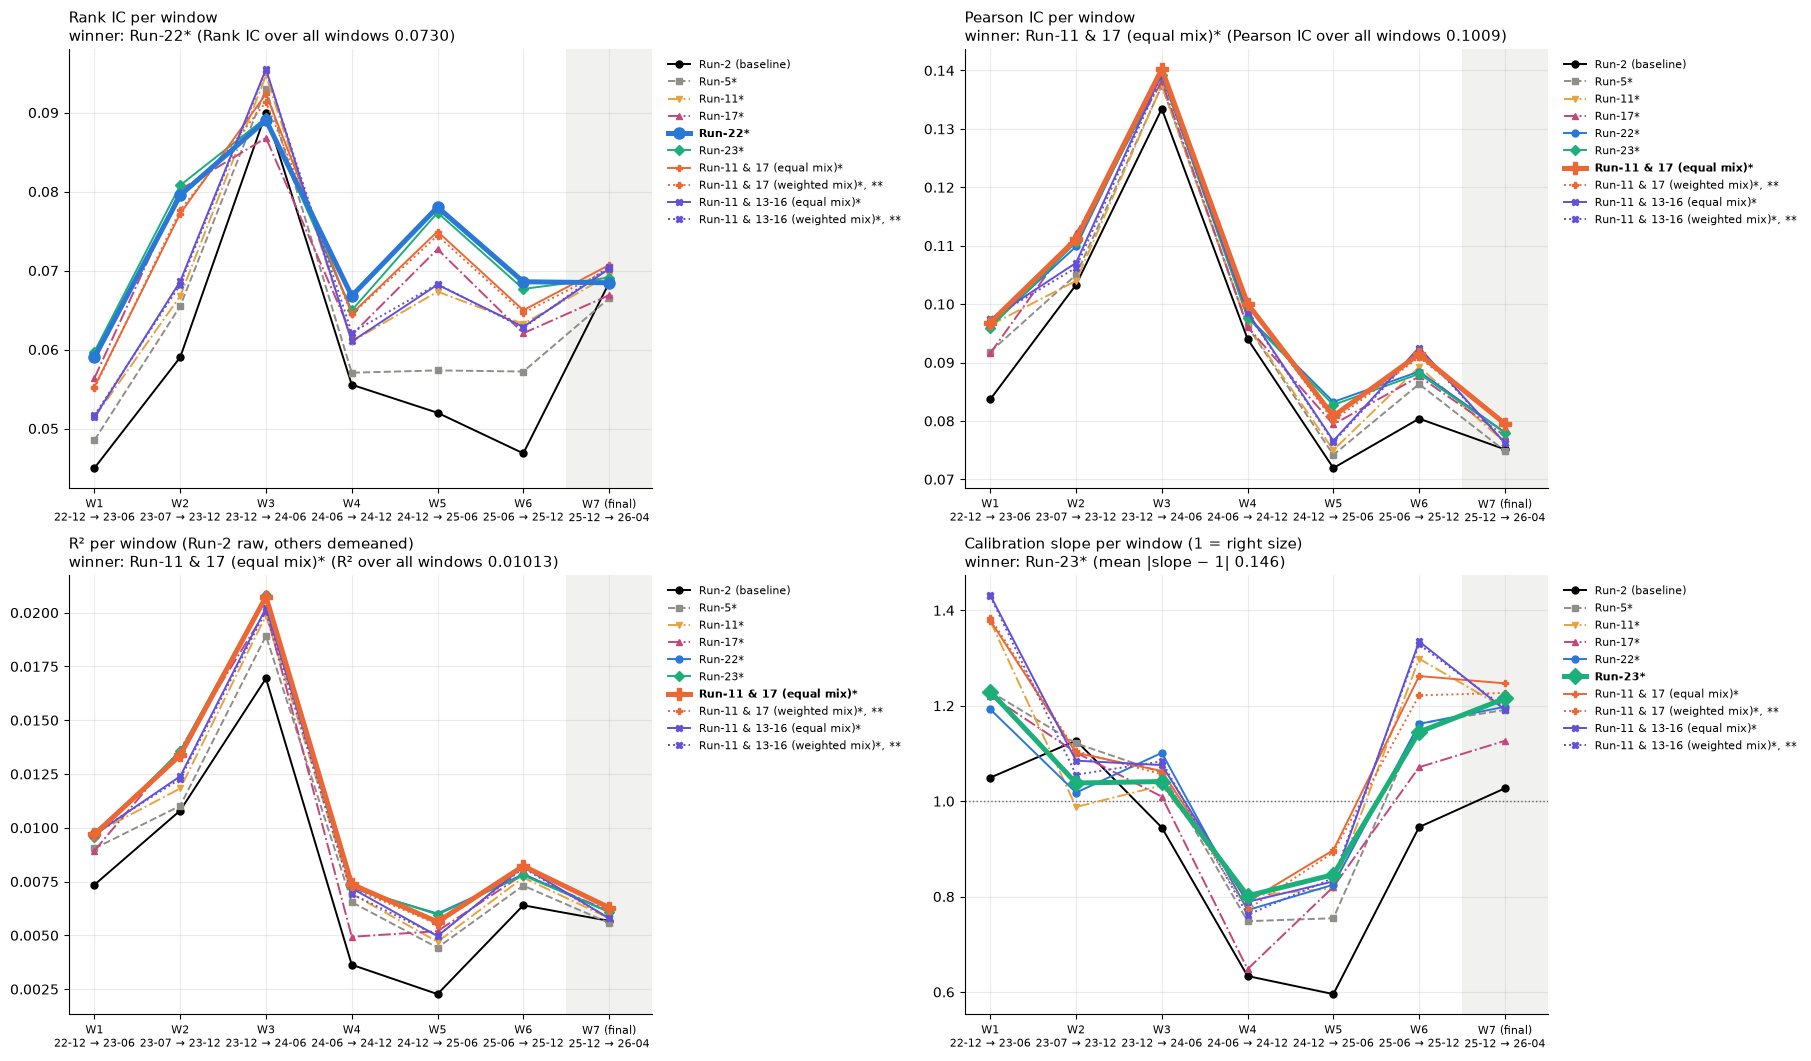

In [11]:
import matplotlib.pyplot as plt

LABELS = {
    "run-2": "Run-2 (baseline)", "run-5": "Run-5*", "run-11": "Run-11*", "run-17": "Run-17*",
    "run-22": "Run-22*", "run-23": "Run-23*", "mix-11-17-equal": "Run-11 & 17 (equal mix)*",
    "mix-11-17-fitted": "Run-11 & 17 (weighted mix)*, **",
    "lagmix-equal": "Run-11 & 13-16 (equal mix)*", "lagmix-fitted": "Run-11 & 13-16 (weighted mix)*, **",
}
STYLE = {  # Fixed per column (colour, line style, marker); a mix's two weightings share a colour.
    "run-2": ("#000000", "-", "o"), "run-5": ("#8f8e88", "--", "s"),
    "run-11": ("#e8a33d", "-.", "v"), "run-17": ("#c4467a", "-.", "^"),
    "run-22": ("#2a78d6", "-", "o"), "run-23": ("#1baf7a", "-", "D"),
    "mix-11-17-equal": ("#eb6834", "-", "P"), "mix-11-17-fitted": ("#eb6834", ":", "P"),
    "lagmix-equal": ("#6250d6", "-", "X"), "lagmix-fitted": ("#6250d6", ":", "X"),
}
PANELS = [  # (title, per-window key, winner key, winner = max / min, rule, format)
    ("Rank IC per window", "window_rank_ic", "rank_ic", max, "Rank IC over all windows", ".4f"),
    ("Pearson IC per window", "window_ic", "ic", max, "Pearson IC over all windows", ".4f"),
    ("R² per window (Run-2 raw, others demeaned)", "window_r2", "r2", max, "R² over all windows", ".5f"),
    ("Calibration slope per window (1 = right size)", "window_slope", "slope_dev", min, "mean |slope − 1|", ".3f"),
]
THIN, BOLD = 1.4, 3.6
ticks = list(range(1, 8))
tick_labels = [f"W{k}{' (final)' if k == 7 else ''}\n{s[2:7]} → {e[2:7]}"
               for k, (s, e) in enumerate(zip(STARTS, ENDS, strict=True), start=1)]

fig, axes = plt.subplots(2, 2, figsize=(18, 10.5), layout="constrained")
for ax, (title, key, win_key, pick, rule, fmt) in zip(axes.flat, PANELS, strict=True):
    winner = pick(CANDIDATES, key=lambda c: METRICS[c][win_key])
    ax.axvspan(6.5, 7.5, color="#8f8e88", alpha=0.12, lw=0)
    for c in CANDIDATES:
        color, ls, marker = STYLE[c]
        is_winner = c == winner
        ax.plot(ticks, METRICS[c][key], color=color, ls=ls, marker=marker,
                lw=BOLD if is_winner else THIN, ms=8 if is_winner else 5,
                zorder=4 if is_winner else 2, label=LABELS[c])
    if key == "window_slope":
        ax.axhline(1, color="#52514e", lw=1, ls=":", zorder=1)
    ax.set_title(f"{title}\nwinner: {LABELS[winner]} ({rule} {format(METRICS[winner][win_key], fmt)})",
                 fontsize=11, loc="left")
    ax.set_xticks(ticks, tick_labels, fontsize=8)
    ax.set_xlim(0.7, 7.5)
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    legend = ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8, frameon=False)
    for text, line in zip(legend.get_texts(), legend.get_lines(), strict=True):
        if text.get_text() == LABELS[winner]:
            text.set_fontweight("bold")
            line.set_linewidth(BOLD)
fig.savefig(FINAL_DIR / "plots" / "all_windows_per_window.png", dpi=120, bbox_inches="tight")
plt.show()